In [55]:
%load_ext autoreload
%autoreload 2
import xarray as xr
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
#import geopandas as gpd
import cartopy.crs as ccrs #for plotting
#import sys

# alternative to this is: from acacia_s2s_toolkit.postprocess import *
from acacia_s2s_toolkit.postprocess import (read_netcdf, 
                                            align_obs_to_product,
                                            )
from verify_probabilistic import verify_probabilistic
from verify_deterministic import verify_deterministic


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
nominal_date="20251201"

det_forecast_file=f"./data/det_fcst-hcst_{nominal_date}.nc"
prob_forecast_file=f"./data/prob_fcst-hcst_{nominal_date}.nc"

#this is file with observational data. It is gridded and covers the period of Jan 1981-March 2026
# any file with daily historical data should do, but if you don't have one at hand - you can get this one by:
#get_example_data(data_dir)
obs_file=f"{data_dir}/PRCPTOT_day_CHC_CHIRPS-2.0-0p25_merged.nc"

#we have to provide the name of the variable stored in the obs_file
obs_var="PRCPTOT"

# this is a file with vector data showing the boundaries of the domain - will be used in plotting only, so not strictly necessary
# this one is included in the example data that comes through get_example_data()
domain_shape_file=f"{data_dir}/madagascar.geojson"

# this sets global verbosity variable. True will show runtime feedback 
set_verbose(False)

#deriving secondary parameters
fcst_date=pd.to_datetime(nominal_date)
fcst_date_str=fcst_date.strftime("%Y%m%d")

# constructing names of data files based on the information above
# forecast products file
detfcst_file="{}/{}_{}_{}_{}_detfcst.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)
probfcst_file="{}/{}_{}_{}_{}_probfcst.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)


verbosity is False


In [25]:

#=============================================================
# prelim stuff - reading and organizing data...
# one has to start with this in any pipeline

# reading observed data - this has to be done using the package function
obs_raw=read_netcdf(obs_file, obs_var)


#reading product files
product_det=xr.open_dataset(detfcst_file)
product_prob=xr.open_dataset(probfcst_file)


print("raw data")
print("observed:", obs_raw.sizes)

print("probabilistic product:", product_prob.sizes)
print("deterministic product:", product_det.sizes)


raw data
observed: Frozen({'time': 16467, 'latitude': 58, 'longitude': 36})
probabilistic product: Frozen({'edge': 2, 'effective_lead_time': 3, 'latitude': 58, 'longitude': 36, 'category': 3, 'valid_time': 1, 'hcst_valid_time': 20})
deterministic product: Frozen({'valid_time': 1, 'effective_lead_time': 3, 'latitude': 58, 'longitude': 36, 'hcst_valid_time': 20})


In [44]:
#processing obs to match forecast


obs_asfcst=align_obs_to_product(obs_raw, product_det)

print("obs data in forecast product structure")
print("obs_asfcst: ",obs_asfcst.sizes)
product_det

obs data in forecast product structure
obs_asfcst:  Frozen({'valid_time': 1, 'effective_lead_time': 3, 'latitude': 58, 'longitude': 36})


<xarray.Dataset> Size: 4MB
Dimensions:              (valid_time: 1, effective_lead_time: 3, latitude: 58,
                          longitude: 36, hcst_valid_time: 20)
Coordinates:
  * valid_time           (valid_time) datetime64[ns] 8B 2025-12-01
  * effective_lead_time  (effective_lead_time) timedelta64[ns] 24B 0 days ......
  * latitude             (latitude) float32 232B -25.88 -25.62 ... -11.88 -11.62
  * longitude            (longitude) float32 144B 42.62 42.88 ... 51.12 51.38
  * hcst_valid_time      (hcst_valid_time) datetime64[ns] 160B 2005-12-01 ......
Data variables:
    fcst_mean            (valid_time, effective_lead_time, latitude, longitude) float64 50kB ...
    fcst_anomaly         (valid_time, effective_lead_time, latitude, longitude) float64 50kB ...
    fcst_anomaly_pct     (valid_time, effective_lead_time, latitude, longitude) float64 50kB ...
    hcst_mean            (hcst_valid_time, effective_lead_time, latitude, longitude) float64 1MB ...
    hcst_anomaly         (hcst_valid_time, effective_lead_time, latitude, longitude) float64 1MB ...
    hcst_anomaly_pct     (hcst_valid_time, effective_lead_time, latitude, longitude) float64 1MB ...
    obs                  (hcst_valid_time, effective_lead_time, latitude, longitude) float32 501kB ...
    clim_obs             (effective_lead_time, latitude, longitude) float32 25kB ...
    skill_corr           (effective_lead_time, latitude, longitude) float64 50kB ...
    skill_rmse           (effective_lead_time, latitude, longitude) float64 50kB ...
    skill_bias           (effective_lead_time, latitude, longitude) float64 50kB ...
Attributes:
    regrid_direction:      coarse_to_fine
    regrid_method:         bilinear
    regrid_nan_threshold:  0.5
    aggregation_method:    sum
    aggregation_window:    7
    product:               deterministic
    units:                 kg m-2 s-1
    hindcast_period:       2005-2024
    n_hindcast_years:      20
    clim_from:             obs

In [56]:
fskill_prob=verify_probabilistic(product_prob, obs_asfcst) 

(Text(0.5, 0.98, 'Probabilistic forecast issued on 20251201 with 0 lead time'),)

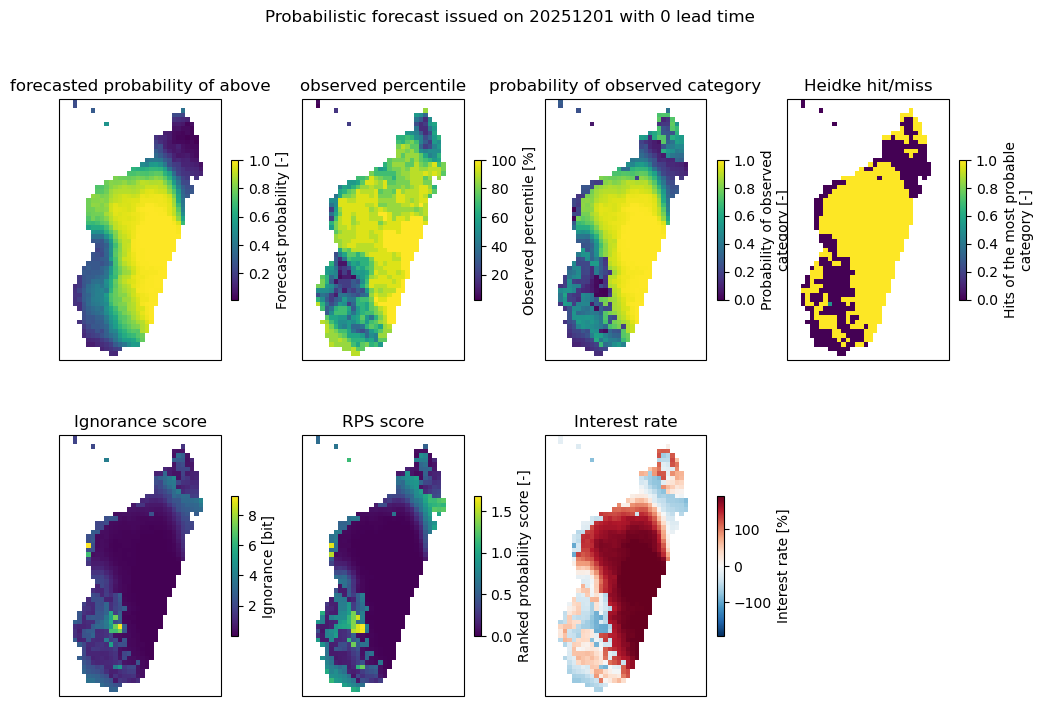

In [66]:
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(0, "D")

#above normal
category=2

#now plotting
fig=plt.figure(figsize=(12,8))

pl=fig.add_subplot(2,4,1, projection=ccrs.PlateCarree())
product_prob["fcst_prob"].sel(effective_lead_time=effective_lead_time, category=category).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("forecasted probability of above")

pl=fig.add_subplot(2,4,2, projection=ccrs.PlateCarree())
fskill_prob["obs_percentile"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("observed percentile")

pl=fig.add_subplot(2,4,3, projection=ccrs.PlateCarree())
fskill_prob["prob_observed"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("probability of observed category")

pl=fig.add_subplot(2,4,4, projection=ccrs.PlateCarree())
fskill_prob["heidke_hits"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Heidke hit/miss")

pl=fig.add_subplot(2,4,5, projection=ccrs.PlateCarree())
fskill_prob["ignorance"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Ignorance score")

pl=fig.add_subplot(2,4,6, projection=ccrs.PlateCarree())
fskill_prob["rps"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("RPS score")

pl=fig.add_subplot(2,4,7, projection=ccrs.PlateCarree())
fskill_prob["interest_rate"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Interest rate")

plt.suptitle(f"Probabilistic forecast issued on {fcst_date_str} with {lt} lead time"), 

In [58]:
fskill_det=verify_deterministic(product_det, obs_asfcst)
fskill_det

<xarray.Dataset> Size: 201kB
Dimensions:              (longitude: 36, latitude: 58, valid_time: 1,
                          effective_lead_time: 3)
Coordinates:
  * longitude            (longitude) float32 144B 42.62 42.88 ... 51.12 51.38
  * latitude             (latitude) float32 232B -25.88 -25.62 ... -11.88 -11.62
  * valid_time           (valid_time) datetime64[ns] 8B 2025-12-01
  * effective_lead_time  (effective_lead_time) timedelta64[ns] 24B 0 days ......
Data variables:
    obs                  (valid_time, effective_lead_time, latitude, longitude) float32 25kB ...
    obs_percentile       (effective_lead_time, latitude, longitude, valid_time) float64 50kB ...
    error                (valid_time, effective_lead_time, latitude, longitude) float64 50kB ...
    error_pct            (valid_time, effective_lead_time, latitude, longitude) float64 50kB ...
    obs_anomaly          (valid_time, effective_lead_time, latitude, longitude) float32 25kB ...
    bias                 (valid_time, effective_lead_time) float64 24B -8.055...
    bias_pct             (valid_time, effective_lead_time) float64 24B -12.12...
    mae                  (valid_time, effective_lead_time) float64 24B 19.38 ...
    rmse                 (valid_time, effective_lead_time) float64 24B 26.41 ...
    acc                  (valid_time, effective_lead_time) float64 24B 0.7778...
    msss                 (valid_time, effective_lead_time) float64 24B 0.7429...
    sign_agreement       (valid_time, effective_lead_time) float64 24B 0.7539...
Attributes:
    product:  deterministic
    units:    kg m-2 s-1

(Text(0.5, 0.98, 'Deterministic forecast issued on 20251201 with 0 lead time'),)

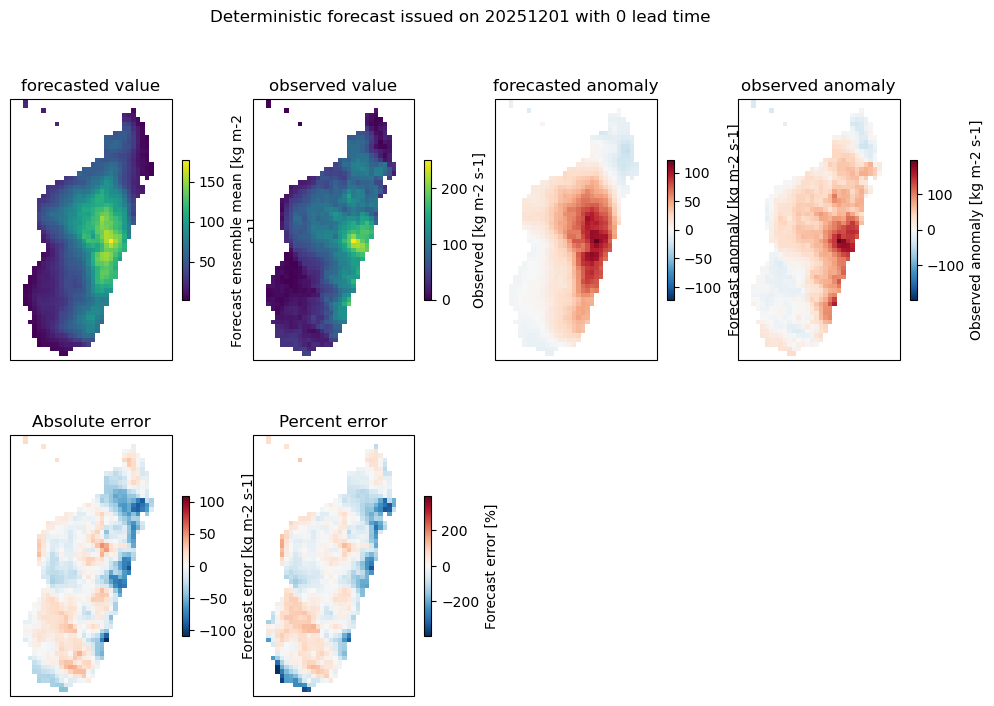

In [65]:
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
lt=0
effective_lead_time=pd.to_timedelta(lt, "D")

#above normal
category=2

#now plotting
fig=plt.figure(figsize=(12,8))

pl=fig.add_subplot(2,4,1, projection=ccrs.PlateCarree())
product_det["fcst_mean"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("forecasted value")

pl=fig.add_subplot(2,4,2, projection=ccrs.PlateCarree())
fskill_det["obs"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("observed value")

pl=fig.add_subplot(2,4,3, projection=ccrs.PlateCarree())
product_det["fcst_anomaly"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("forecasted anomaly")

pl=fig.add_subplot(2,4,4, projection=ccrs.PlateCarree())
fskill_det["obs_anomaly"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("observed anomaly")

pl=fig.add_subplot(2,4,5, projection=ccrs.PlateCarree())
fskill_det["error"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Absolute error")


pl=fig.add_subplot(2,4,6, projection=ccrs.PlateCarree())
fskill_det["error_pct"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Percent error")

plt.suptitle(f"Deterministic forecast issued on {fcst_date_str} with {lt} lead time"), 